In [2]:
from langgraph.graph import StateGraph, START , END
# from langchain_openai import ChatOpenAI
from langchain_groq import ChatGroq
from typing import TypedDict
from dotenv import load_dotenv
import os


In [ ]:
GROQ_API_KEY = os.getenv("GROQ_API_KEY")

model = ChatGroq(
    model="openai/gpt-oss-120b",
    temperature=0,
    groq_api_key="your API key"
)
print(model)

metadata={'lc_versions': {'langchain-core': '1.6.7', 'langchain': '1.4.3'}} profile={'name': 'GPT OSS 120B', 'release_date': '2025-08-05', 'last_updated': '2026-05-27', 'open_weights': True, 'max_input_tokens': 131072, 'max_output_tokens': 65536, 'text_inputs': True, 'image_inputs': False, 'audio_inputs': False, 'video_inputs': False, 'text_outputs': True, 'image_outputs': False, 'audio_outputs': False, 'video_outputs': False, 'reasoning_output': True, 'tool_calling': True, 'structured_output': True, 'attachment': False, 'temperature': True} client=<groq.resources.chat.completions.Completions object at 0x000001E22AC59550> async_client=<groq.resources.chat.completions.AsyncCompletions object at 0x000001E22AC59FD0> model_name='openai/gpt-oss-120b' temperature=1e-08 model_kwargs={} groq_api_key=SecretStr('**********')


In [4]:
class Blogstate(TypedDict):
    title : str
    outline : str
    content : str 
    


In [5]:
def outline_fn(state : Blogstate) -> Blogstate:
    # fetch title
    title = state['title']
     
    #call llm gen outline
    prompt = f'Generate a detailed outline for a blog on the topic - {title}'
    outline = model.invoke(prompt).content

    #update state
    state['outline'] = outline

    return state




In [6]:
def content_fn(state : Blogstate) -> Blogstate:
    # fetch title
    title = state['title']
    outline = state['outline']

    #call llm gen blog
    prompt = f'Generate a detailed blog on the - {title} using the following outline \n {outline}'
    content = model.invoke(prompt).content

    #update state
    state['content'] = content

    return state




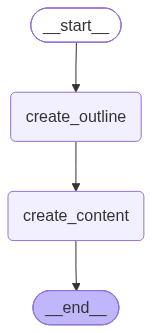

In [7]:
graph = StateGraph(Blogstate)

#nodes 
graph.add_node('create_outline', outline_fn)
graph.add_node('create_content', content_fn)

#edges
graph.add_edge(START, 'create_outline')
graph.add_edge('create_outline', 'create_content')
graph.add_edge('create_content', END)

#COMPILE
PC_workflow = graph.compile()

from IPython.display import Image
Image(PC_workflow.get_graph().draw_mermaid_png())





In [8]:
initial_state = {'title': 'Rise of AI in India'}

Final_state = PC_workflow.invoke(initial_state)

print(Final_state)

{'title': 'Rise of AI in India', 'outline': '**Blog Title:**  \n*The Rise of AI in India: Drivers, Impact, Challenges & the Road Ahead*\n\n---\n\n## 1. Introduction  \n- **Hook:** A striking statistic or anecdote (e.g., “India is projected to host 20‑30\u202f% of the world’s AI talent by 2030”).  \n- **Why it matters:** Briefly explain AI’s global relevance and why India’s trajectory is a game‑changer for the economy, society, and the tech ecosystem.  \n- **Thesis statement:** Outline the blog’s purpose – to map the forces propelling AI in India, showcase real‑world impact, discuss hurdles, and envision the future.\n\n---\n\n## 2. Historical Context – From Early Adoption to a Full‑Blown AI Boom  \n| Period | Milestones | Key Players |\n|--------|------------|-------------|\n| **1990‑2005** | First AI research labs in IITs & ISI; early NLP & expert systems | IIT Madras, IIT Bombay, ISI Kolkata |\n| **2006‑2014** | Emergence of data‑centric research; start‑up incubators | NASSCOM, IIT‑ba

In [11]:
print(Final_state['outline'])

**Blog Title:**  
*The Rise of AI in India: Drivers, Impact, Challenges & the Road Ahead*

---

## 1. Introduction  
- **Hook:** A striking statistic or anecdote (e.g., “India is projected to host 20‑30 % of the world’s AI talent by 2030”).  
- **Why it matters:** Briefly explain AI’s global relevance and why India’s trajectory is a game‑changer for the economy, society, and the tech ecosystem.  
- **Thesis statement:** Outline the blog’s purpose – to map the forces propelling AI in India, showcase real‑world impact, discuss hurdles, and envision the future.

---

## 2. Historical Context – From Early Adoption to a Full‑Blown AI Boom  
| Period | Milestones | Key Players |
|--------|------------|-------------|
| **1990‑2005** | First AI research labs in IITs & ISI; early NLP & expert systems | IIT Madras, IIT Bombay, ISI Kolkata |
| **2006‑2014** | Emergence of data‑centric research; start‑up incubators | NASSCOM, IIT‑based incubators |
| **2015‑2020** | Deep learning wave; launch of A